# EDA geoespacial — avisos de Agua de Hermosillo vs. red hidrográfica

¿Existe relación espacial entre la ubicación de los avisos de Agua de Hermosillo y las características de la red hidrográfica de la ciudad?

Fuentes:
- `publicaciones_aguah.csv`: tipo de evento por publicación (`restablecimiento`, `corte_programado`, `emergencia`, `pipas`, `otro`)
- `ubicaciones_aviso.csv`: lugares mencionados en las publicaciones (nombres de colonia y cruces de calles geocodificados)
- `colonias_hermosillo.gpkg`: polígonos de colonias del DCAH, puente espacial de las menciones de colonia
- `subc_hermosillo.gpkg`: capas `hl`, `dr` y `ha` del consolidado de las 4 subcuencas (INEGI 1:50 000)

**Zona de estudio:** el círculo mínimo que envuelve los cruces geocodificados, más 2 km de margen. Cubre toda el área urbana incluyendo los huecos entre asentamientos del DCAH (los 1,467 cruces caen dentro o a ≤0.6 km de la ciudad; ninguno en Bahía de Kino ni Miguel Alemán).

Nota semántica: `hl` es la red de **drenaje natural** (cauces), no la red de agua potable. La relación se interpreta hidrológicamente (proximidad a cauces y cuerpos de agua), no como fallas de tubería.

In [127]:
import geopandas as gpd
import pandas as pd
import shapely
import matplotlib.pyplot as plt
from pathlib import Path

In [128]:
DATA = Path("../../data/processed")
SUBC = DATA / "inegi/hidrografia_hermosillo/subc_hermosillo.gpkg"

publicaciones = pd.read_csv(DATA / "aguah/publicaciones_aguah.csv")
ubicaciones = pd.read_csv(DATA / "aguah/ubicaciones_aviso.csv", dtype={"colonia_id": str})

colonias = gpd.read_file(DATA / "aguah/colonias_hermosillo.gpkg")
hl = gpd.read_file(SUBC, layer="hl")
dr = gpd.read_file(SUBC, layer="dr")
ha = gpd.read_file(SUBC, layer="ha")

print(f"{len(publicaciones)} publicaciones, {len(ubicaciones)} menciones")
print(f"{len(colonias)} colonias | hl: {len(hl)}, dr: {len(dr)}, ha: {len(ha)}")

5200 publicaciones, 16261 menciones
783 colonias | hl: 46518, dr: 36, ha: 744


## Preparación

Se une cada mención con el `event_type` de su publicación. Las menciones tienen dos formas espaciales: los **cruces geocodificados** ya traen punto (`lat`/`lon`); las **menciones de colonia** se resuelven a su polígono vía `colonia_id`. Todo se reproyecta a EPSG:6372 (metros) para medir distancias.

Sobre la confianza: `match_method` indica cómo se resolvió cada mención — `colonia_con_marcador` (el texto dice "colonia X", alta confianza), `colonia_en_catalogo` (nombre suelto emparejado al catálogo, ~74% de las menciones, menor confianza), `cruce_geocodificado` y `unmatched`.

In [129]:
METRICO = 6372  # Conica Conforme de Lambert ITRF2008, metros

menciones = ubicaciones.merge(
    publicaciones[["post_id", "event_type"]], on="post_id", how="left"
)

geocodificados = menciones["match_method"] == "cruce_geocodificado"
cruces = gpd.GeoDataFrame(
    menciones[geocodificados].reset_index(drop=True),
    geometry=gpd.points_from_xy(
        menciones.loc[geocodificados, "lon"],
        menciones.loc[geocodificados, "lat"],
    ),
    crs="EPSG:4326",
).to_crs(epsg=METRICO)

menciones_colonia = menciones[menciones["location_type"] == "colonia"]

# Zona de estudio: circulo minimo que envuelve los cruces + 2 km de margen
zona = shapely.minimum_bounding_circle(cruces.union_all()).buffer(1000)
radio_km = (zona.area / 3.141592653589793) ** 0.5 / 1000

colonias_m = colonias.to_crs(epsg=METRICO)
hl_m = hl.to_crs(epsg=METRICO)
dr_m = dr.to_crs(epsg=METRICO)
ha_m = ha.to_crs(epsg=METRICO)

hl_zona = gpd.clip(hl_m, zona)
ha_zona = gpd.clip(ha_m, zona)
dr_zona = gpd.clip(dr_m, zona)

print(f"{len(cruces)} cruces geocodificados | {len(menciones_colonia)} menciones de colonia")
print(f"Zona de estudio: radio aprox. {radio_km:.1f} km")
print(f"Dentro de la zona -> hl: {len(hl_zona)}, ha: {len(ha_zona)}, dr: {len(dr_zona)}")

1467 cruces geocodificados | 14411 menciones de colonia
Zona de estudio: radio aprox. 11.8 km
Dentro de la zona -> hl: 1158, ha: 28, dr: 4


## Resumen de las menciones

Distribución de las menciones por tipo de lugar y tipo de evento de la publicación, más el desglose por método de resolución.

In [130]:
print(
    pd.crosstab(
        menciones["event_type"], menciones["location_type"], margins=True, margins_name="total"
    )
)
print()
print(menciones["match_method"].value_counts())

location_type     colonia  cruce  total
event_type                             
corte_programado     1689     64   1753
emergencia           2519    310   2829
otro                 9537   1407  10944
pipas                  56     28     84
restablecimiento      610     41    651
total               14411   1850  16261

match_method
colonia_en_catalogo     12031
colonia_con_marcador     2380
cruce_geocodificado      1467
unmatched                 383
Name: count, dtype: int64


## Mapa: cruces mencionados vs. red hidrográfica en la zona de estudio

La red `hl` dentro de la zona, diferenciando cauces de orden bajo (<4) de los colectores principales (≥4, orden de Strahler), más los cuerpos de agua `ha` y puntos de drenaje `dr`. Los cruces se colorean por `event_type`.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))

gpd.GeoSeries([zona], crs=hl_m.crs).boundary.plot(
    ax=ax, color="gray", linewidth=1, linestyle="--", label="Zona de estudio"
)
hl_zona[hl_zona["ORDER_1"] < 3].plot(
    ax=ax, color="lightsteelblue", linewidth=0.6, label="hl orden < 4"
)
hl_zona[hl_zona["ORDER_1"] >= 3].plot(
    ax=ax, color="steelblue", linewidth=1.8, label="hl orden >= 4 (colectores)"
)
ha_zona.plot(ax=ax, color="deepskyblue", edgecolor="none")
dr_zona.plot(ax=ax, color="red", markersize=100, marker="*", label="dr")

# un color explicito por event_type para poder armar la 2a leyenda
tipos = cruces["event_type"].value_counts().index
paleta = dict(zip(tipos, plt.get_cmap("tab10").colors))
for t, c in paleta.items():
    cruces[cruces["event_type"] == t].plot(
        ax=ax, color=c, markersize=25, alpha=0.7
    )

# dos leyendas: la de la red arriba a la derecha y la de tipos abajo a la izquierda
leyenda_red = ax.legend(loc="upper right")
ax.add_artist(leyenda_red)

from matplotlib.lines import Line2D

ax.legend(
    handles=[
        Line2D(
            [0], [0], marker="o", color="none", markerfacecolor=c,
            markeredgecolor="none", markersize=8, label=t,
        )
        for t, c in paleta.items()
    ],
    loc="lower left", title="event_type",
)

ax.set_title("Cruces mencionados en avisos vs. red hidrografica (zona de estudio)")
ax.set_axis_off()
plt.show()

## Distancia a la red hidrográfica

Distancia de cada **cruce geocodificado** a la geometría más cercana de `hl`, `ha` y `dr` dentro de la zona de estudio (en metros). La zona incluye la hidrografía que el recorte a asentamientos omitía en los huecos entre colonias.

In [132]:
def distancia_a(puntos, capa, columna):
    unidos = gpd.sjoin_nearest(
        puntos, capa[["geometry"]], how="left", distance_col=columna
    )
    # sjoin_nearest duplica la fila si el punto empata entre dos geometrias
    return unidos[~unidos.index.duplicated(keep="first")].drop(columns="index_right")

cruces = cruces.pipe(distancia_a, hl_zona, "dist_hl_m")
cruces = cruces.pipe(distancia_a, ha_zona, "dist_ha_m")
cruces = cruces.pipe(distancia_a, dr_zona, "dist_dr_m")

print(cruces[["dist_hl_m", "dist_ha_m", "dist_dr_m"]].describe().round(1))

       dist_hl_m  dist_ha_m  dist_dr_m
count     1467.0     1467.0     1467.0
mean       543.9     2890.3     4110.9
std        527.2     1438.9     1748.2
min          0.1       70.1       10.7
25%        133.9     1822.4     2799.2
50%        377.8     2928.7     4103.9
75%        791.8     3954.1     5497.3
max       2361.0     6085.4     8880.4


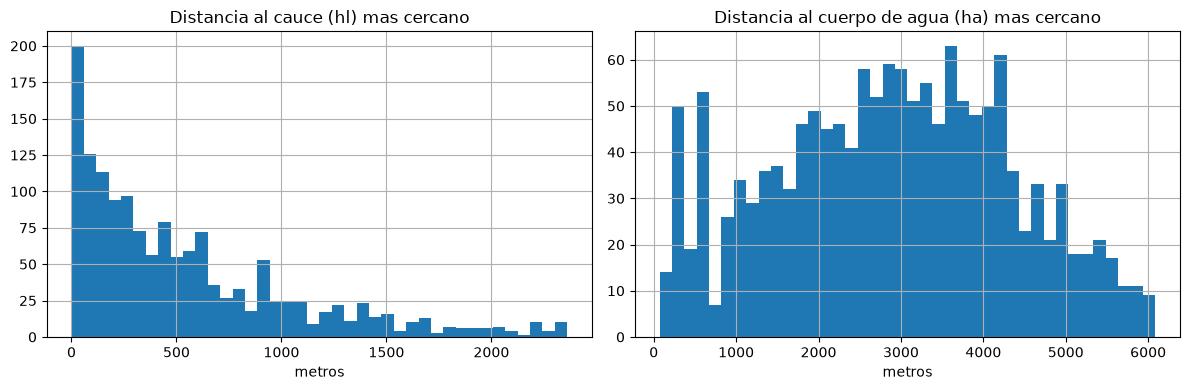

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cruces["dist_hl_m"].hist(bins=40, ax=axes[0])
axes[0].set_xlabel("metros")
axes[0].set_title("Distancia al cauce (hl) mas cercano")

cruces["dist_ha_m"].hist(bins=40, ax=axes[1])
axes[1].set_xlabel("metros")
axes[1].set_title("Distancia al cuerpo de agua (ha) mas cercano")

plt.tight_layout()
plt.show()

## Exposición por colonia

Para cada colonia de la ciudad (`locality_code == "0001"`): kilómetros de cauce `hl` que la cruzan, área de cuerpos de agua `ha` dentro, y si contiene el punto de drenaje `dr`. Se cruza con cuántas publicaciones la mencionan.

In [134]:
colonias_cd = colonias_m[colonias_m["locality_code"] == "0001"][["colonia_id", "geometry"]]

# sjoin + interseccion contra la red completa del consolidado
# (overlay descartaria los tramos lineales dentro del poligono)
pares = gpd.sjoin(hl_m[["geometry"]], colonias_cd, how="inner", predicate="intersects")
geom_colonia = pares["colonia_id"].map(colonias_cd.set_index("colonia_id")["geometry"])
tramos = pares.geometry.intersection(geom_colonia)
km_cauce = tramos.length.groupby(pares["colonia_id"]).sum() / 1000

ha_en_colonia = gpd.overlay(colonias_cd, ha_m[["geometry"]], how="intersection")
area_ha = (
    ha_en_colonia.assign(km2=lambda d: d.geometry.area / 1e6)
    .groupby("colonia_id")["km2"].sum()
)

dr_en_colonia = gpd.sjoin(
    dr_m[["geometry"]], colonias_cd, how="inner", predicate="within"
)["colonia_id"]

expo = (
    colonias_cd.set_index("colonia_id")
    .assign(km_cauce=km_cauce, area_ha_km2=area_ha)
    .fillna({"km_cauce": 0, "area_ha_km2": 0})
)
expo["tiene_dr"] = expo.index.isin(dr_en_colonia)

# Publicaciones y menciones por colonia (deduplicadas por publicacion)
expo["publicaciones"] = menciones_colonia.groupby("colonia_id")["post_id"].nunique()
expo["menciones"] = menciones_colonia.groupby("colonia_id").size()
expo[["publicaciones", "menciones"]] = expo[["publicaciones", "menciones"]].fillna(0)

print(expo[["km_cauce", "area_ha_km2", "publicaciones", "menciones"]].describe().round(2))

       km_cauce  area_ha_km2  publicaciones  menciones
count    762.00       762.00         762.00     762.00
mean       0.25         0.00          18.84      18.84
std        0.69         0.01          34.92      34.92
min        0.00         0.00           0.00       0.00
25%        0.00         0.00           0.00       0.00
50%        0.00         0.00           5.00       5.00
75%        0.28         0.00          24.00      24.00
max       10.97         0.18         389.00     389.00


In [135]:
print("Correlacion de Spearman entre exposicion y menciones:")
print(
    expo[["km_cauce", "area_ha_km2", "publicaciones", "menciones"]]
    .corr(method="spearman")
    .round(2)
)
print()
print(f"Colonias con al menos un tramo de cauce: {(expo['km_cauce'] > 0).sum()} de {len(expo)}")
print(f"Colonias con cuerpo de agua: {(expo['area_ha_km2'] > 0).sum()}")
print(f"Colonias con el punto de drenaje: {expo['tiene_dr'].sum()}")

Correlacion de Spearman entre exposicion y menciones:
               km_cauce  area_ha_km2  publicaciones  menciones
km_cauce           1.00         0.08           0.04       0.04
area_ha_km2        0.08         1.00          -0.03      -0.03
publicaciones      0.04        -0.03           1.00       1.00
menciones          0.04        -0.03           1.00       1.00

Colonias con al menos un tramo de cauce: 354 de 762
Colonias con cuerpo de agua: 14
Colonias con el punto de drenaje: 1


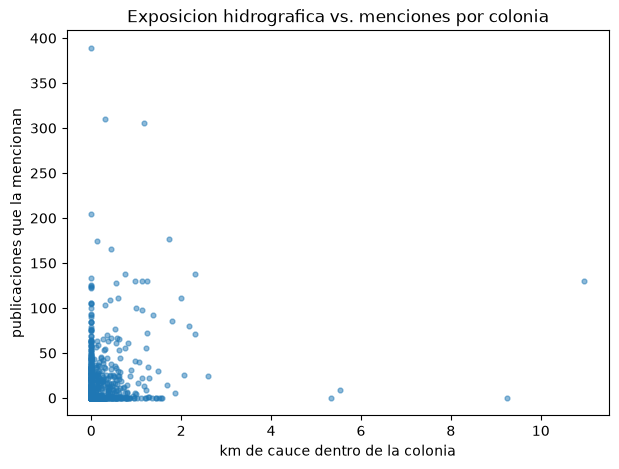

In [136]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(expo["km_cauce"], expo["publicaciones"], s=12, alpha=0.5)
ax.set_xlabel("km de cauce dentro de la colonia")
ax.set_ylabel("publicaciones que la mencionan")
ax.set_title("Exposicion hidrografica vs. menciones por colonia")
plt.show()

## Orden de Strahler (ORDER_1)

`ORDER_1` es la clasificación de Strahler del cauce a nivel subcuenca: `1` = cauces de cabecera, `5`–`7` = colectores principales; `-1` = segmentos sin clasificar. Medir distancia a "cualquier `hl`" mezcla ramalitos de drenaje con el cauce mayor — aquí se separa la distancia al colector de orden ≥4 más cercano.

In [137]:
tabla_orden = (
    hl_zona.assign(km=lambda d: d.geometry.length / 1000)
    .groupby("ORDER_1")["km"]
    .agg(segmentos="count", km_total="sum")
    .round(1)
)
print("Distribucion de ORDER_1 en la zona de estudio:")
print(tabla_orden)

colectores = hl_zona[hl_zona["ORDER_1"] >= 4][["geometry"]]
cruces = cruces.pipe(distancia_a, colectores, "dist_hl_orden4_m")

Distribucion de ORDER_1 en la zona de estudio:
         segmentos  km_total
ORDER_1                     
-1              12       4.2
 1             563     483.4
 2             303     185.3
 3             180     112.8
 4              68      50.9
 5              15      11.1
 6               8      11.1
 7               9       7.3


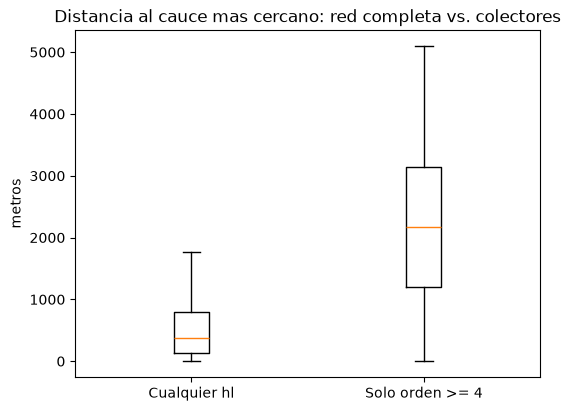

In [138]:
fig, ax = plt.subplots(figsize=(6, 4.5))

ax.boxplot(
    [cruces["dist_hl_m"], cruces["dist_hl_orden4_m"]],
    tick_labels=["Cualquier hl", "Solo orden >= 4"],
    showfliers=False,
)
ax.set_ylabel("metros")
ax.set_title("Distancia al cauce mas cercano: red completa vs. colectores")
plt.show()

## Por tipo de evento

¿Se acercan más a la red los cruces de ciertos tipos de aviso? Y a nivel colonia: ¿las colonias con más emergencias tienen más exposición hidrográfica?

In [139]:
print(
    cruces.groupby("event_type")[["dist_hl_m", "dist_hl_orden4_m", "dist_ha_m"]]
    .median()
    .round(1)
)

                  dist_hl_m  dist_hl_orden4_m  dist_ha_m
event_type                                              
corte_programado      352.3            2179.1     2912.7
emergencia            348.4            2275.4     2806.9
otro                  380.5            2143.0     2955.4
pipas                 537.1            1723.1     2819.0
restablecimiento      483.9            2797.8     2375.5


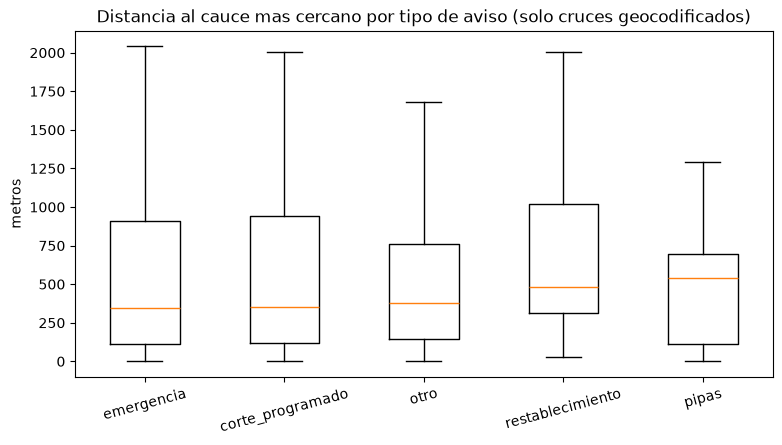

In [140]:
fig, ax = plt.subplots(figsize=(9, 4.5))

orden = cruces.groupby("event_type")["dist_hl_m"].median().sort_values().index
datos = [cruces.loc[cruces["event_type"] == t, "dist_hl_m"] for t in orden]
ax.boxplot(datos, tick_labels=orden, showfliers=False)

ax.set_title("Distancia al cauce mas cercano por tipo de aviso (solo cruces geocodificados)")
ax.set_ylabel("metros")
ax.tick_params(axis="x", labelrotation=15)
plt.show()

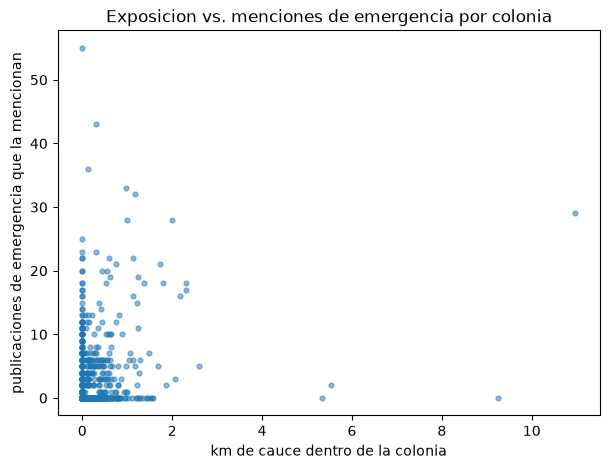

Spearman (km_cauce vs. emergencias por colonia): 0.11


In [141]:
# Emergencias por colonia vs. exposicion hidrografica
emergencias = (
    menciones_colonia[menciones_colonia["event_type"] == "emergencia"]
    .groupby("colonia_id")["post_id"].nunique()
)
expo["emergencias"] = emergencias.reindex(expo.index, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(expo["km_cauce"], expo["emergencias"], s=12, alpha=0.5)
ax.set_xlabel("km de cauce dentro de la colonia")
ax.set_ylabel("publicaciones de emergencia que la mencionan")
ax.set_title("Exposicion vs. menciones de emergencia por colonia")
plt.show()

rho = expo[["km_cauce", "emergencias"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman (km_cauce vs. emergencias por colonia): {rho:.2f}")

## Comentarios

**¿Existe relación espacial entre los avisos y la red hidrográfica? La evidencia apunta a que es débil.**

- **La zona de estudio** (círculo de ~12.8 km de radio sobre los cruces + 2 km) contiene 1,374 segmentos `hl`, 28 cuerpos de agua `ha` y 4 puntos `dr` — más del triple de red que el recorte a asentamientos (437), porque incluye la hidrografía en los huecos entre colonias.
- **Los cruces mencionados están cerca de la red, pero como todo en la ciudad.** La distancia mediana al cauce `hl` más cercano es **378 m** (IQR 134–792 m, máx. ~2.4 km); con la red completa bajó solo ~40 m respecto al recorte urbano (416 m), es decir, la hidrografía omitida en los huecos apenas movía la medición. Con una red tan densa, cualquier punto urbano queda a <1 km de algún cauce: la cercanía es propiedad de la red, no de los avisos.
- **Los avisos "operativos" son los más cercanos a la red fina.** `emergencia` (mediana 348 m) y `corte_programado` (352 m) quedan ~130–190 m más cerca que `restablecimiento` (484 m) y `pipas` (537 m) — una dirección consistente pero una diferencia pequeña para afirmar un patrón.
- **No se acercan especialmente a los colectores principales.** La mediana de distancia al cauce de orden ≥4 es ~2.1–2.8 km por tipo de evento (vs. ~350–540 m a la red fina): los avisos se reparten por la ciudad sin seguir los cauces mayores.
- **La exposición por colonia tampoco predice las menciones.** Solo 354 de 762 colonias contienen tramo de cauce (máx. ~11 km); Spearman km-cauce vs. publicaciones = **0.04**, y vs. emergencias = **0.11** — ruido, no señal.
- **Lectura alternativa:** dónde se reportan avisos parece explicarse más por la estructura urbana y las prácticas de comunicación de Agua de Hermosillo (los volantes listan tablas de colonias) que por la hidrografía.

**Limitaciones explícitas**

- `hl` es la red de drenaje **natural** de INEGI (cauces 1:50k), no la red de agua potable: cualquier cercanía se interpreta hidrológicamente, no como evidencia sobre tuberías.
- Las menciones son lugares nombrados en publicaciones de Facebook, no incidentes confirmados en campo; la cobertura refleja lo que Agua de Hermosillo decide publicar.
- Solo 4 puntos `dr` caen en la zona (de 36 del consolidado): la distancia a `dr` describe cercanía a esos pocos puntos, no a la infraestructura de drenaje en general.
- La mayoría de las menciones de colonia se resolvieron por `colonia_en_catalogo` (nombre suelto, sin el marcador "colonia"/"fracc."), el método menos seguro; 383 menciones quedaron `unmatched`.
- Una publicación lista muchas colonias a la vez (los volantes de corte traen tablas), por lo que los conteos por colonia no equivalen a número de eventos — por eso `publicaciones` y `menciones` coinciden por colonia.
- La cercanía espacial por sí sola no implica causalidad.

## Análisis por sector (Norte / Centro / Sur)

Se divide la ciudad en los tres macro-sectores del PDU asignados en la libreta `05` (`notebook_experimentation_data/colonias_hermosillo.csv`) y se repite el cruce exposición hidrográfica ↔ menciones **por sector**: si la relación entre km de cauce (`hl`), cuerpos de agua (`ha`) y los avisos es uniforme o cambia entre zonas de la ciudad.

In [142]:
sectores = pd.read_csv(
    Path("notebook_experimentation_data/colonias_hermosillo.csv"),
    usecols=["colonia_id", "sector"],
    dtype={"colonia_id": str},
)

# sector por colonia (expo ya trae km_cauce, area_ha_km2, menciones, emergencias)
expo_sector = expo.join(sectores.set_index("colonia_id")["sector"])
print(f"colonias con sector: {expo_sector['sector'].notna().sum()} de {len(expo_sector)}")

# sector por cruce: el punto cae dentro del poligono de la colonia
colonias_sector = colonias_cd.merge(sectores, on="colonia_id", how="left")
cruces = gpd.sjoin(
    cruces, colonias_sector[["sector", "geometry"]], how="left", predicate="within"
).drop(columns="index_right")
cruces = cruces[~cruces.index.duplicated(keep="first")]  # borde entre colonias

print(f"cruces dentro de una colonia con sector: {cruces['sector'].notna().sum()} de {len(cruces)}")

colonias con sector: 762 de 762
cruces dentro de una colonia con sector: 1370 de 1467


In [143]:
# exposicion hidrografica y menciones agregadas por sector
por_sector = (
    expo_sector.dropna(subset=["sector"])
    .groupby("sector")
    .agg(
        colonias=("sector", "size"),
        area_km2=("geometry", lambda g: g.area.sum() / 1e6),
        km_cauce=("km_cauce", "sum"),
        area_ha_km2=("area_ha_km2", "sum"),
        publicaciones=("publicaciones", "sum"),
        menciones=("menciones", "sum"),
        emergencias=("emergencias", "sum"),
    )
)
por_sector["cruces"] = cruces["sector"].value_counts()
por_sector["km_cauce_por_km2"] = por_sector["km_cauce"] / por_sector["area_km2"]
por_sector["ha_por_km2"] = por_sector["area_ha_km2"] / por_sector["area_km2"]
por_sector["menciones_por_km2"] = por_sector["menciones"] / por_sector["area_km2"]
por_sector["cruces_por_km_cauce"] = por_sector["cruces"] / por_sector["km_cauce"]
por_sector.round(2)

,colonias,area_km2,km_cauce,area_ha_km2,publicaciones,menciones,emergencias,cruces,km_cauce_por_km2,ha_por_km2,menciones_por_km2,cruces_por_km_cauce
sector,,,,,,,,,,,,
Centro,178,36.91,11.37,0.14,3353.0,3353.0,564,422,0.31,0.0,90.83,37.11
Norte,398,55.58,112.44,0.21,8955.0,8955.0,1628,665,2.02,0.0,161.13,5.91
Sur,186,39.95,64.74,0.06,2045.0,2045.0,322,283,1.62,0.0,51.19,4.37


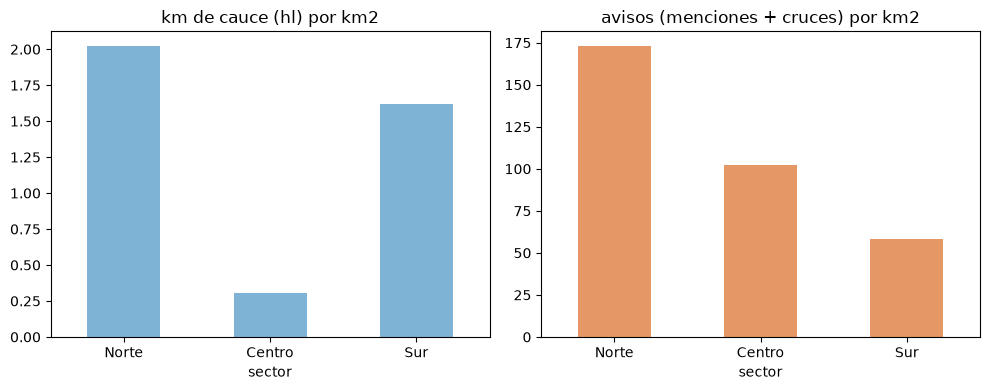

In [144]:
# comparativo por sector: exposicion normalizada vs. actividad de avisos
# avisos = menciones de colonia + cruces geocodificados mencionados
por_sector["avisos_por_km2"] = (
    por_sector["menciones"] + por_sector["cruces"]
) / por_sector["area_km2"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

por_sector["km_cauce_por_km2"].reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=axes[0], rot=0, color="#7fb3d5"
)
axes[0].set_title("km de cauce (hl) por km2")
por_sector["avisos_por_km2"].reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=axes[1], rot=0, color="#e59866"
)
axes[1].set_title("avisos (menciones + cruces) por km2")

plt.tight_layout()
plt.show()

Spearman exposicion vs. menciones por sector (por colonia):
  Norte: km_cauce rho=0.06  (398 colonias)
  Norte: area_ha_km2 rho=-0.11  (398 colonias)
  Centro: km_cauce rho=0.01  (178 colonias)
  Centro: area_ha_km2 rho=-0.04  (178 colonias)
  Sur: km_cauce rho=-0.01  (186 colonias)
  Sur: area_ha_km2 rho=0.13  (186 colonias)


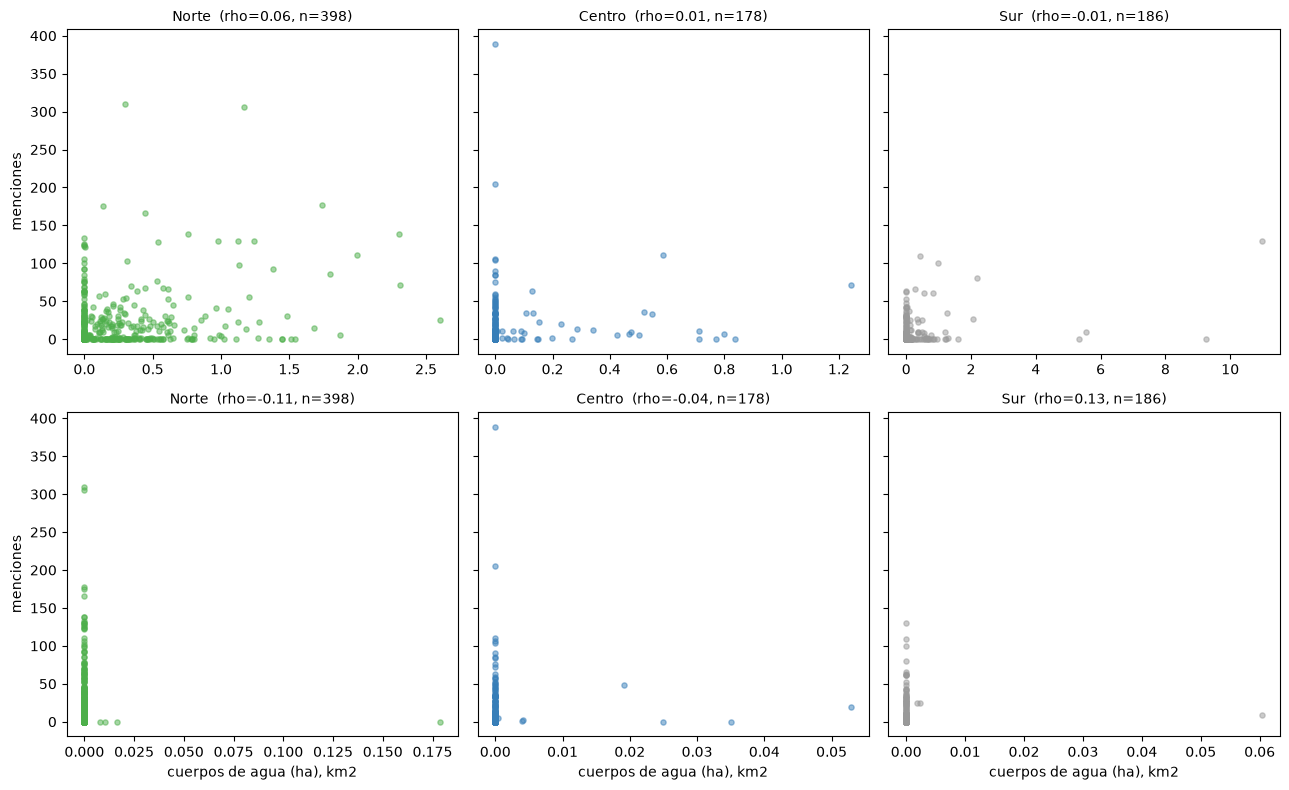

In [145]:
# exposicion vs. menciones por colonia, un panel por sector: si la pendiente
# cambia entre sectores, la relacion aviso~hidrografia no es uniforme
colores_sector = {"Norte": "#4daf4a", "Centro": "#377eb8", "Sur": "#999999"}
orden = ["Norte", "Centro", "Sur"]
exposiciones = [("km_cauce", "km de cauce (hl)"), ("area_ha_km2", "cuerpos de agua (ha), km2")]

fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharey="row")

print("Spearman exposicion vs. menciones por sector (por colonia):")
for j, s in enumerate(orden):
    d = expo_sector[expo_sector["sector"] == s]
    for i, (exposicion, etiqueta) in enumerate(exposiciones):
        ax = axes[i, j]
        ax.scatter(d[exposicion], d["menciones"], s=14, alpha=0.5, color=colores_sector[s])
        rho = d[[exposicion, "menciones"]].corr(method="spearman").iloc[0, 1]
        ax.set_title(f"{s}  (rho={rho:.2f}, n={len(d)})", fontsize=10)
        if i == 1:
            ax.set_xlabel(etiqueta)
        if j == 0:
            ax.set_ylabel("menciones")
        print(f"  {s}: {exposicion} rho={rho:.2f}  ({len(d)} colonias)")

plt.tight_layout()
plt.show()

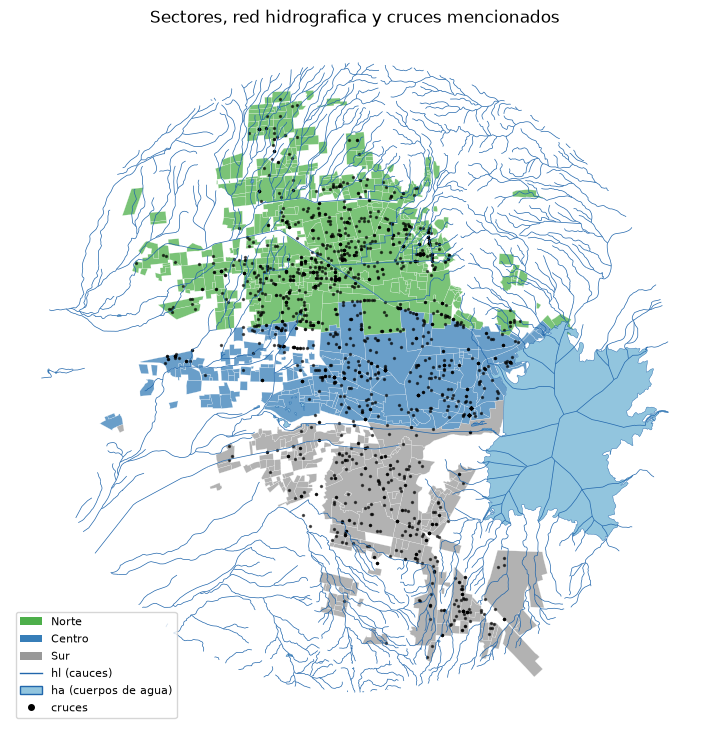

In [146]:
# mapa: colonias por sector, red hidrografica y cruces mencionados
fig, ax = plt.subplots(figsize=(9, 9))
for s, c in colores_sector.items():
    expo_sector[expo_sector["sector"] == s].plot(
        ax=ax, color=c, edgecolor="white", linewidth=0.2, alpha=0.75
    )
hl_zona.plot(ax=ax, color="#2166ac", linewidth=0.5)
ha_zona.plot(ax=ax, color="#92c5de", edgecolor="#2166ac", linewidth=0.3)
cruces.plot(ax=ax, color="black", markersize=2, alpha=0.6)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ax.legend(
    handles=[
        *[Patch(facecolor=c, label=s) for s, c in colores_sector.items()],
        Line2D([0], [0], color="#2166ac", lw=1, label="hl (cauces)"),
        Patch(facecolor="#92c5de", edgecolor="#2166ac", label="ha (cuerpos de agua)"),
        Line2D([0], [0], marker="o", color="black", lw=0, markersize=4, label="cruces"),
    ],
    loc="lower left",
    fontsize=8,
)
ax.set_title("Sectores, red hidrografica y cruces mencionados")
ax.set_axis_off()
plt.show()

## Preguntas por sector

Cuatro métricas comparables entre Norte, Centro y Sur:

1. **Avisos por densidad de cauce** — (cruces + menciones) / (km de cauce por km²): ¿dónde genera más avisos la misma densidad de red `hl`?
2. **Distancia mínima promedio aviso↔cauce** — ¿qué tan cerca de un cauce `hl` caen los cruces mencionados en cada sector?
3. **Distancia mínima promedio aviso↔cuerpo de agua** — lo mismo contra la capa `ha`.
4. **Avisos por km de colector** — (cruces + menciones) / km de cauce con `ORDER_1 > 3` (colectores principales): ¿los avisos se concentran donde hay cauce mayor?

Nota: en el Centro `km_cauce_por_km2` es muy chico (0.31) — el denominador pequeño infla las razones 1 y 4; leer como "los avisos del Centro no dependen de la red `hl`".

Distancia al cuerpo de agua ha / colector orden>=4 mas cercano (m):
       dist_ha_m                 dist_hl_orden4_m                
           count    mean  median            count    mean  median
sector                                                           
Centro       422  1821.0  1905.0              422  3044.0  3127.0
Norte        665  3776.0  3899.0              665  1406.0  1259.0
Sur          283  2375.0  2326.0              283  2614.0  2683.0


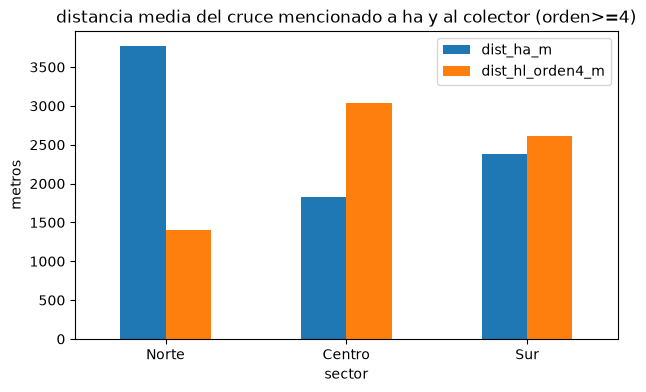

In [149]:
# P3: distancia minima promedio aviso <-> cuerpo de agua (ha) por sector
# (se agrega el colector de orden >=4 como referencia para la P4)
dist_ha = cruces.groupby("sector")[["dist_ha_m", "dist_hl_orden4_m"]].agg(
    ["count", "mean", "median"]
).round(0)
print("Distancia al cuerpo de agua ha / colector orden>=4 mas cercano (m):")
print(dist_ha)

fig, ax = plt.subplots(figsize=(7, 4))
cruces.groupby("sector")[["dist_ha_m", "dist_hl_orden4_m"]].mean().reindex(orden).plot.bar(
    ax=ax, rot=0
)
ax.set_title("distancia media del cruce mencionado a ha y al colector (orden>=4)")
ax.set_ylabel("metros")
plt.show()

        avisos  km_colector  avisos_por_km_colector
sector                                             
Centro  3775.0          0.0                     inf
Norte   9620.0          9.2                  1042.5
Sur     2328.0          2.8                   835.9
(inf = el sector no tiene ningun km de colector dentro de sus colonias)


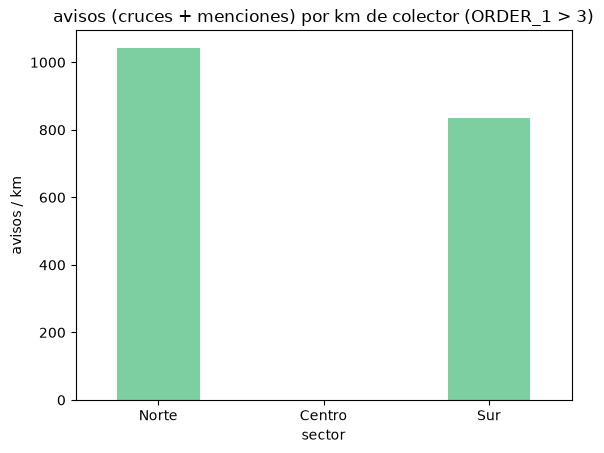

In [150]:
# P4: (cruces + menciones) / km de cauce con ORDER_1 > 3 (colectores) por sector
# misma logica que km_cauce: solo tramos dentro de los poligonos de colonias
poligonos_sector = colonias_sector.dropna(subset=["sector"]).dissolve(by="sector")
colectores = hl_m[hl_m["ORDER_1"] > 3][["geometry"]]
km_colector = {
    s: gpd.clip(colectores, geom).length.sum() / 1000
    for s, geom in poligonos_sector.geometry.items()
}

por_sector["km_colector"] = pd.Series(km_colector)
por_sector["avisos_por_km_colector"] = por_sector["avisos"] / por_sector["km_colector"]

print(por_sector[["avisos", "km_colector", "avisos_por_km_colector"]].round(1))
print("(inf = el sector no tiene ningun km de colector dentro de sus colonias)")

# inf no se puede graficar: se omite la barra de ese sector
por_sector["avisos_por_km_colector"].replace(float("inf"), float("nan")).reindex(orden).plot.bar(
    rot=0, color="#7dcea0"
)
plt.title("avisos (cruces + menciones) por km de colector (ORDER_1 > 3)")
plt.ylabel("avisos / km")
plt.show()

In [151]:
# resumen: las 4 metricas juntas por sector
resumen_sector = por_sector.reindex(orden)[
    ["avisos", "km_cauce_por_km2", "avisos_por_densidad_cauce",
     "km_colector", "avisos_por_km_colector"]
].join(dist_hl[["mean", "median"]].rename(columns={"mean": "dist_hl_media_m", "median": "dist_hl_mediana_m"}))
resumen_sector["dist_ha_media_m"] = cruces.groupby("sector")["dist_ha_m"].mean().round(0)
resumen_sector.round(1)

,avisos,km_cauce_por_km2,avisos_por_densidad_cauce,km_colector,avisos_por_km_colector,dist_hl_media_m,dist_hl_mediana_m,dist_ha_media_m
sector,,,,,,,,
Norte,9620.0,2.0,4754.7,9.2,1042.5,328.0,257.0,3776.0
Centro,3775.0,0.3,12254.5,0.0,inf,1019.0,894.0,1821.0
Sur,2328.0,1.6,1436.6,2.8,835.9,482.0,334.0,2375.0


## Análisis temporal: ¿los avisos se concentran en la temporada de lluvias?

Como el Centro resultó ajeno a la red `hl`, el análisis se acota a **Norte y Sur**.

**Hipótesis:** la mayoría de los avisos caen entre **agosto y octubre** — la temporada de lluvias en Hermosillo, cuando los cauces se activan.

In [152]:
# avisos con fecha: menciones de colonia + cruces geocodificados, con su sector
menciones_sector = menciones_colonia.merge(sectores, on="colonia_id", how="left")

avisos_sector = pd.concat(
    [
        menciones_sector[["post_id", "event_type", "sector"]],
        pd.DataFrame(cruces[["post_id", "event_type", "sector"]]),
    ]
).merge(publicaciones[["post_id", "year", "month"]], on="post_id", how="left")

# acotar a Norte y Sur (el Centro es ajeno a la red hl)
avisos_ns = avisos_sector[avisos_sector["sector"].isin(["Norte", "Sur"])]

print(f"avisos con sector: {avisos_sector['sector'].notna().sum()} | Norte+Sur: {len(avisos_ns)}")
print(f"sin fecha: {avisos_ns['month'].isna().sum()}")
print(avisos_ns.groupby("sector")["post_id"].nunique().rename("publicaciones distintas"))

avisos con sector: 15723 | Norte+Sur: 11948
sin fecha: 0
sector
Norte    2316
Sur       963
Name: publicaciones distintas, dtype: int64


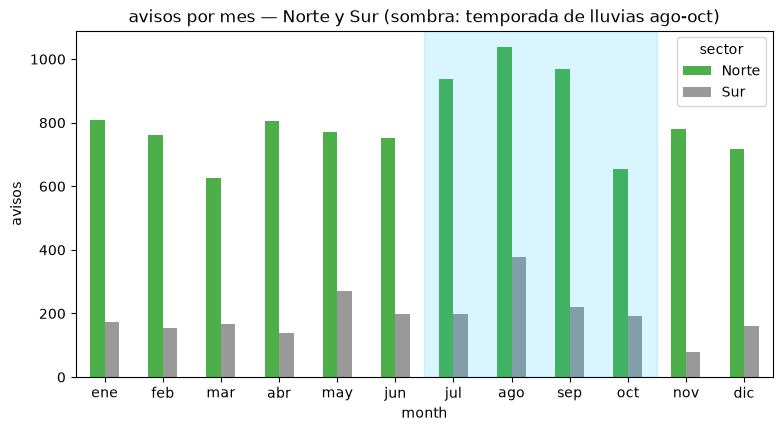

% de avisos ago-oct por sector: {'Norte': '27.7%', 'Sur': '33.9%'} | global: 28.9%


In [153]:
# distribucion mensual de avisos por sector (todos los anios agrupados)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

por_mes = (
    avisos_ns.groupby(["month", "sector"]).size().unstack("sector").reindex(range(1, 13))
)

fig, ax = plt.subplots(figsize=(9, 4.5))
por_mes.plot.bar(ax=ax, rot=0, color=[colores_sector["Norte"], colores_sector["Sur"]])
ax.axvspan(6.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)  # ago-oct
ax.set_xticklabels(MESES)
ax.set_title("avisos por mes — Norte y Sur (sombra: temporada de lluvias ago-oct)")
ax.set_ylabel("avisos")
plt.show()

lluvias = avisos_ns["month"].between(8, 10)
print(
    "% de avisos ago-oct por sector:",
    avisos_ns.groupby("sector").apply(
        lambda d: f"{d['month'].between(8, 10).mean() * 100:.1f}%", include_groups=False
    ).to_dict(),
    "| global:", f"{lluvias.mean() * 100:.1f}%",
)

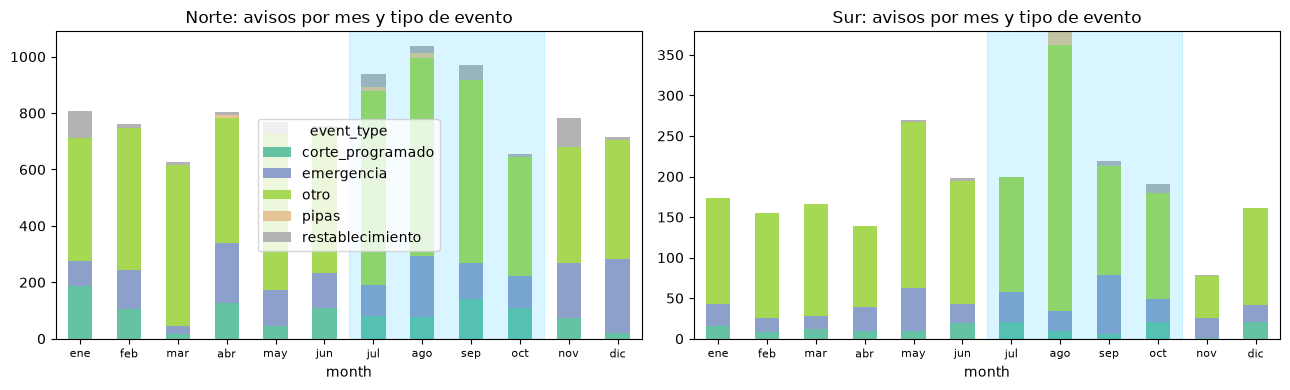

In [154]:
# ¿el patron mensual viene de las emergencias o del ruido administrativo ('otro')?
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, s in zip(axes, ["Norte", "Sur"]):
    d = avisos_ns[avisos_ns["sector"] == s]
    (
        d.groupby(["month", "event_type"]).size().unstack("event_type")
        .reindex(range(1, 13))
        .plot.bar(ax=ax, rot=0, stacked=True, colormap="Set2", legend=(s == "Norte"))
    )
    ax.axvspan(6.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)
    ax.set_xticklabels(MESES, fontsize=8)
    ax.set_title(f"{s}: avisos por mes y tipo de evento")
plt.tight_layout()
plt.show()

In [155]:
# ¿el patron se repite cada anio o es un solo periodo lluvioso?
por_anio_mes = (
    avisos_ns.groupby(["year", "month"]).size().unstack("month").reindex(columns=range(1, 13))
)
por_anio_mes.columns = MESES
por_anio_mes = por_anio_mes.fillna(0).astype(int)
print("avisos por anio y mes (Norte + Sur):")
print(por_anio_mes)
print()
print(
    "% jul-oct por anio:",
    (por_anio_mes[["jul","ago", "sep", "oct"]].sum(axis=1) / por_anio_mes.sum(axis=1) * 100)
    .round(1)
    .to_dict(),
)

avisos por anio y mes (Norte + Sur):
      ene  feb  mar  abr  may  jun  jul  ago  sep  oct  nov  dic
year                                                            
2020    0    0    0    0    0    0    0    0    0    0    0   96
2021   88   73   46   74  115   32   67   33   62  170  186  133
2022  195   75  139  124  133  168  162  355   48   69  109  130
2023  156  155  104   57  193   83  164   41  391   51  172  177
2024  108  246   54   49  108  176  163  277  165  248  174   98
2025  101  130  171  403  357  242  316  615  445  307  218  244
2026  333  238  277  237  134  250  265   96   77    0    0    0

% jul-oct por anio: {2020: 0.0, 2021: 30.8, 2022: 37.1, 2023: 37.1, 2024: 45.7, 2025: 47.4, 2026: 23.0}


### Solo emergencias

Las menciones tipo `otro` dominan el volumen y pueden ser ruido administrativo. Se repite el análisis mensual solo con `event_type == "emergencia"` — la firma más cercana a eventos reales de falla/inundación.

avisos de emergencia Norte+Sur: 2119 (17.7% del total)


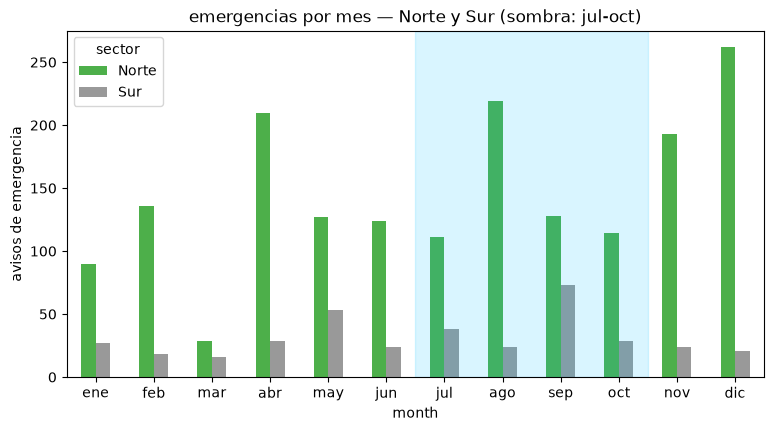

% de emergencias jul-oct por sector: {'Norte': '26.4%', 'Sur': '33.5%'} | global: 27.7%


In [124]:
# solo emergencias: distribucion mensual por sector
emerg_ns = avisos_ns[avisos_ns["event_type"] == "emergencia"]
print(f"avisos de emergencia Norte+Sur: {len(emerg_ns)} "
      f"({len(emerg_ns) / len(avisos_ns) * 100:.1f}% del total)")

por_mes_em = (
    emerg_ns.groupby(["month", "sector"]).size().unstack("sector").reindex(range(1, 13))
)

fig, ax = plt.subplots(figsize=(9, 4.5))
por_mes_em.plot.bar(ax=ax, rot=0, color=[colores_sector["Norte"], colores_sector["Sur"]])
ax.axvspan(6.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)
ax.set_xticklabels(MESES)
ax.set_title("emergencias por mes — Norte y Sur (sombra: jul-oct)")
ax.set_ylabel("avisos de emergencia")
plt.show()

print(
    "% de emergencias jul-oct por sector:",
    emerg_ns.groupby("sector").apply(
        lambda d: f"{d['month'].between(8, 10).mean() * 100:.1f}%", include_groups=False
    ).to_dict(),
    "| global:", f"{emerg_ns['month'].between(8, 10).mean() * 100:.1f}%",
)

In [126]:
# emergencias por anio y mes: ¿el pico ago-oct se repite?
em_anio_mes = (
    emerg_ns.groupby(["year", "month"]).size().unstack("month").reindex(columns=range(1, 13))
)
em_anio_mes.columns = MESES
em_anio_mes = em_anio_mes.fillna(0).astype(int)
print("emergencias por anio y mes (Norte + Sur):")
print(em_anio_mes)
print()
print(
    "% jul-oct por anio:",
    (em_anio_mes[["jul","ago", "sep", "oct"]].sum(axis=1) / em_anio_mes.sum(axis=1) * 100)
    .round(1)
    .to_dict(),
)

emergencias por anio y mes (Norte + Sur):
      ene  feb  mar  abr  may  jun  jul  ago  sep  oct  nov  dic
year                                                            
2020    0    0    0    0    0    0    0    0    0    0    0    7
2021    4   14    0    5   38    5   30    0    3   26   44   65
2022    9    6    8   77   11   20   31  120   31    3   26   78
2023   15   18    5   38   52   45   16    9   90   27  100   94
2024   26   78   22   14   39   29   28   25   36   60   46   25
2025   39   37    6   99   33   17   23   80   41   27    1   14
2026   24    1    4    6    7   32   21    9    0    0    0    0

% ago-oct por anio: {2020: 0.0, 2021: 12.4, 2022: 36.7, 2023: 24.8, 2024: 28.3, 2025: 35.5, 2026: 8.7}
